# 425 – qGAN Experiments: What Makes Training Work?

GANs are famous for being hard to train.  In this notebook we change **one setting at a time**
on the 1-D log-normal problem of `421` and compare the relative entropy curves:

1. **Balance between the players** – discriminator steps and learning rates.
2. **Generator depth** – one or two ansatz repetitions.
3. **Ansatz type** – `efficient_su2` ($R_Y$ + $R_Z$) versus `real_amplitudes` ($R_Y$ only).

Each run takes 100 epochs (≈ 2–3 minutes); the whole notebook needs about 10 minutes.
Because training uses shots, your curves may differ slightly – the trends are what matter.

**Prerequisites:** `421`.

In [1]:
# === BACKEND SETUP (qiskit_backend_config) ===
# -----------------------------------------------
# Common backend helper — works with Qiskit 2.x / qiskit-aer / qiskit-ibm-runtime.
# Provides drop-in replacements for the removed Aer, BasicAer, execute(), and IBMQ.
#
# HOW TO SELECT A BACKEND
# -----------------------
# Simulator (default, runs locally — no credentials needed):
#   BACKEND_NAME = "qasm_simulator"        # shot-based measurements
#   BACKEND_NAME = "statevector_simulator" # full statevector
#   BACKEND_NAME = "unitary_simulator"     # full unitary matrix
#
# Real IBM hardware (requires IBM Quantum account):
#   Set the environment variable:  IBM_QUANTUM_TOKEN=<your_token>
#   Then choose a device, e.g.:
#   BACKEND_NAME = "ibm_brisbane"
#   BACKEND_NAME = "least_busy"  # auto-pick least-busy device
#
import sys, os
sys.path.insert(0, os.path.dirname(os.path.abspath('__file__')))
from qiskit_backend_config import (get_backend, execute, Aer, BasicAer,
                                   IBMQ, least_busy, job_monitor, assemble, combine)

# ── Choose your backend here ──────────────────────────────────────────────
BACKEND_NAME = "qasm_simulator"  # change to a device name for real hardware
# ── (Optional) IBM Quantum token — leave empty to use env var or saved creds
IBM_QUANTUM_TOKEN = os.environ.get("IBM_QUANTUM_TOKEN", "")

# Build the backend object used throughout this notebook
_token_arg = IBM_QUANTUM_TOKEN if IBM_QUANTUM_TOKEN else None
backend = get_backend(BACKEND_NAME, token=_token_arg)
print(f'Backend ready: {backend}')


Backend ready: LegacyAerSimulator('aer_simulator')


In [2]:
import time
import numpy as np
import matplotlib.pyplot as plt
import torch

# the qGAN building blocks written out step by step in 421, packaged for re-use
from qml_qgan import (discretize, generator_circuit, make_generator, Discriminator,
                      train_qgan, generated_distribution, plot_history)

torch.manual_seed(42)
rng = np.random.default_rng(71)
grid_elements, prob_data = discretize(rng.lognormal(mean=1, sigma=1, size=1000), [0., 7.], [3])

def run(label, reps=1, ansatz='efficient_su2', num_epochs=100, **train_kwargs):
    """Train a fresh qGAN and return its history."""
    torch.manual_seed(42)
    qc = generator_circuit([3], reps=reps, ansatz=ansatz)
    generator = make_generator(qc, seed=42, initial_weights=np.random.default_rng(1).random(qc.num_parameters))
    start = time.time()
    history = train_qgan(generator, Discriminator(1), grid_elements, prob_data,
                         num_epochs=num_epochs, **train_kwargs)
    print(f"{label:45s} {qc.num_parameters:2d} weights  {time.time() - start:5.0f} s   "
          f"final relative entropy {history['rel_entr'][-1]:.3f}")
    return history

def compare(histories, title):
    plt.figure(figsize=(8, 4))
    for label, h in histories.items():
        plt.plot(h['rel_entr'], label=label, lw=2)
    plt.yscale('log')
    plt.title(title); plt.xlabel('epoch'); plt.ylabel('relative entropy (log scale)')
    plt.legend(); plt.grid(alpha=0.3)
    plt.show()

## Experiment 1 – Balancing generator and discriminator

* **balanced** – the settings of `421`: the discriminator learns faster (lr 0.05 vs 0.02) and
  takes 3 steps per generator step.
* **naive** – both learn at the same rate (0.01), one step each.

balanced: lr_D 0.05, 3 D-steps                12 weights     58 s   final relative entropy 0.060


naive: equal lr 0.01, 1 D-step                12 weights     55 s   final relative entropy 0.395


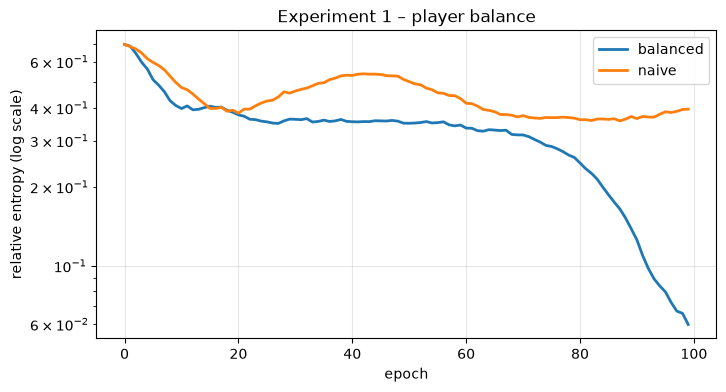

In [3]:
balanced = run('balanced: lr_D 0.05, 3 D-steps')
naive = run('naive: equal lr 0.01, 1 D-step', lr_generator=0.01, lr_discriminator=0.01, d_steps=1)
compare({'balanced': balanced, 'naive': naive}, 'Experiment 1 – player balance')

**Why?**  The generator's gradient says "move probability to where $D$ thinks data is real".
That is only useful if $D$ is close to its *best* answer for the current generator.  In the
naive setting $D$ lags behind, the generator chases an outdated target, and the pair tends to
oscillate rather than converge.

## Experiment 2 – Generator depth

balanced, efficient_su2 reps=2                18 weights    150 s   final relative entropy 0.114


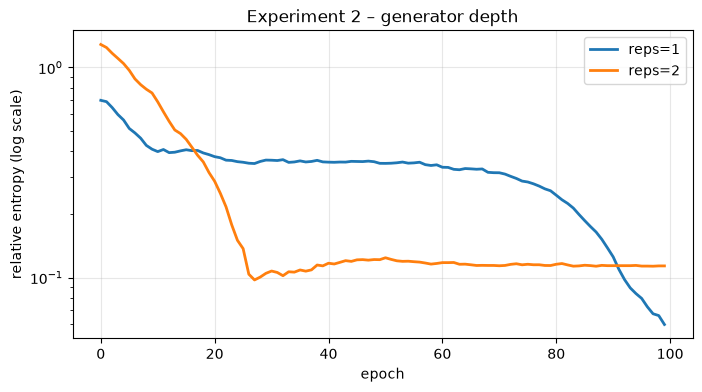

In [4]:
deeper = run('balanced, efficient_su2 reps=2', reps=2)
compare({'reps=1': balanced, 'reps=2': deeper}, 'Experiment 2 – generator depth')

More repetitions mean more weights (12 → 18), more circuits per gradient, and a harder
optimisation landscape.  For a smooth 8-point distribution, one repetition is already
expressive enough – a deeper circuit is not automatically better.

## Experiment 3 – Ansatz type

balanced, real_amplitudes reps=2               9 weights     99 s   final relative entropy 0.471


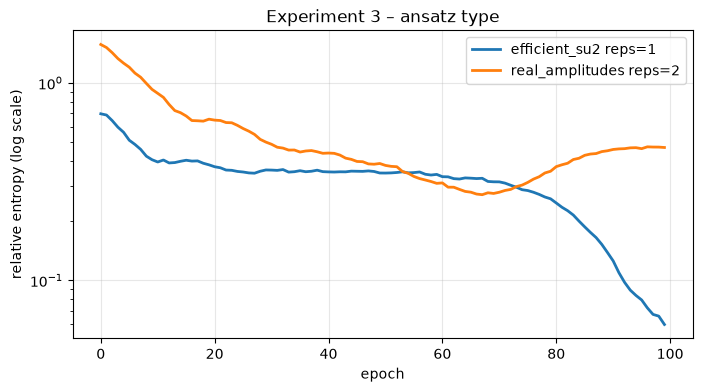

In [5]:
ry_only = run('balanced, real_amplitudes reps=2', reps=2, ansatz='real_amplitudes')
compare({'efficient_su2 reps=1': balanced, 'real_amplitudes reps=2': ry_only},
        'Experiment 3 – ansatz type')

`real_amplitudes` uses only $R_Y$ rotations, so all amplitudes stay real.  That is enough to
represent any probability distribution in principle – but the optimisation path can differ a
lot from `efficient_su2`.

## Summary

| Setting | Lesson |
|---|---|
| discriminator steps / learning rates | the balance between the players decides whether training converges |
| generator depth | more parameters ≠ better; match the circuit to the problem |
| ansatz type | expressive *in principle* is not the same as *easy to train* |

## Try it yourself
1. Run the balanced setting with `d_steps=5`, and with `lr_generator=0.05`.
2. Change the number of shots: `make_generator(qc, shots=500)` and `shots=10_000`.
   How do the speed and the smoothness of the curves change?
3. Repeat Experiment 1 with three different seeds.  Is the difference consistent?

*This notebook replaces an earlier version that ran unit tests of the retired Qiskit Aqua
`QGAN` class.*